# Marconi waterline QC: noon composites, pixel instruments, and SAM vs. Otsu waterlines
csherwood@usgs.gov, 2026-10-27, generated with Claude Opus 5.5

Three things, using the outputs of `make_dems.ipynb`:

1. **Pixel instruments.** The timestack pixels (`c1_timestack.pix`, `c2_timestack.pix`, columns U V) are drawn on
   oblique images, then rectified for every day by intersecting each pixel's ray with that day's DEM, using the
   calibration of that day's images. Positions and DEM elevations go to `pix_xyz_daily.csv` (day, camera,
   eo_file, i, u, v, x, y, z; z is NaN where the ray misses the DEM, and x, y are then at `QC['z_fallback']`).
2. **Daily QC figures** (`fig/qc_days/qc_YYYY-MM-DD.png`): a rectified composite of the c1 and c2 timex images
   closest to local noon, projected onto the day's DEM (blank DEM cells filled from the nearest cell), with
   a. the rectified waterline points of the three-day window colored by assigned elevation (images rejected
   against the DEM in red), and b. the DEM with 1 m contours. The pixel-instrument transects are on both.
   Waterlines that land on dry sand or out on the water stand out against the image.
3. **SAM waterlines** (Segment Anything; Kirillov et al., 2023), prompted with sea points just below the
   horizon and beach points along the image bottom, written to `waterlines_px_sam.csv` in the same format as
   the Otsu file and compared image by image.

Requires (beyond what the earlier notebooks use): torch, torchvision, segment_anything, and a SAM checkpoint.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_dem as md
import marconi_qc as mq
import marconi_movie as mm

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
CAL_DIR = Path(r'F:\crs\proj\marconi_imagery\calibration_parameters')
PIX_DIR = Path(r'F:\crs\proj\marconi_imagery\pixel_locations')
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
WL_CSV = OUT_DIR / 'waterlines_px.csv'
DEM_DIR = OUT_DIR / 'dems'
FIG_DIR = PROJ / 'fig'
QC_DIR = FIG_DIR / 'qc_days'
PIX_CSV = OUT_DIR / 'pix_xyz_daily.csv'
FIRST_DAY, LAST_DAY = None, None       # e.g. '2025-01-20', '2025-03-08'; None = all days in dem_days.csv
QC = mq.QC | {}                        # e.g. {'noon': 13.}
MOVIE = mm.MOVIE | {'xlim': (None, 420200.)}

QC_DIR.mkdir(parents=True, exist_ok=True)
scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
wl_px = pd.read_csv(WL_CSV).groupby('path')
dt = pd.read_csv(OUT_DIR / 'dem_days.csv', parse_dates=['day'])
dt = dt[(dt.day >= pd.Timestamp(FIRST_DAY or dt.day.min())) & (dt.day <= pd.Timestamp(LAST_DAY or dt.day.max()))]
beta = dict(zip(dt.day, dt.beta_used))
status = {r.day: f"{r.status}, {r.n_img_used:.0f} images, slope {r.slope_median:.3f}" if r.status == 'ok' else r.status
          for r in dt.itertuples()}
pix = {c: mq.read_pix(PIX_DIR / f'{c}_timestack.pix') for c in ['c1', 'c2']}
print(len(dt), 'days;', {c: p.shape for c, p in pix.items()})

92 days; {'c1': (7610, 2), 'c2': (2051, 2)}


## Pixel instruments on the oblique images
Check that the pixel columns are U, V (not V, U) and that the transects sit where the timestacks are recorded.

2025-02-21 00:00:00 2 cameras


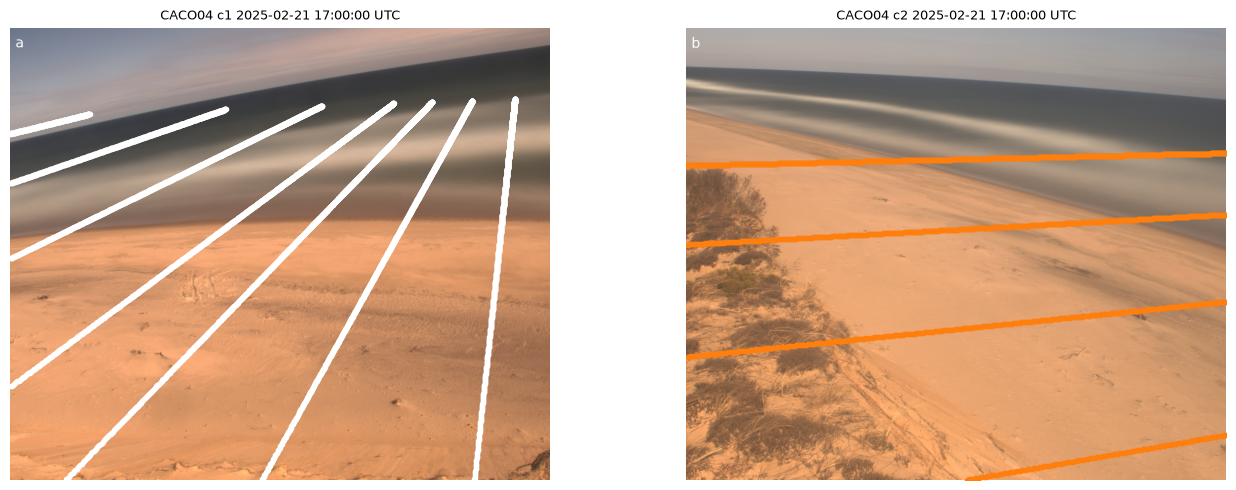

In [8]:
day = dt.loc[dt.n_img_used.idxmax(), 'day']       # the day with the most usable images
rows = mq.noon_images(scan, day, QC)
print(day, len(rows), 'cameras')
fig, ax = plt.subplots(1, len(rows), figsize=(7 * len(rows), 5))
for a, r, l in zip(np.atleast_1d(ax), rows.itertuples(), 'ab'):
    a.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
    a.plot(*pix[r.camera].T,'.',c=QC['pix_colors'][r.camera])
    a.set_title(f'{r.station} {r.camera} {r.time} UTC', fontsize=9)
    a.axis('off')
    a.text(0.01, 0.98, l, transform=a.transAxes, va='top', color='w')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pixel_instruments_oblique.jpg', dpi=120)

## Daily QC figures and rectified pixel instruments
About 2–4 s per day.

In [3]:
pxyz = mq.run_qc_days(list(dt.day), scan, wl_px, CAL_DIR, DEM_DIR, QC_DIR, pix, beta, status, QC, md.CFG, MOVIE)
pxyz.to_csv(PIX_CSV, index=False, float_format='%.3f')
pxyz.groupby('camera')[['x', 'y', 'z']].describe().T

2024-12-09  5282 points
2024-12-10  5282 points
2024-12-11 no daytime images
2024-12-12  17377 points
2024-12-13  28769 points
2024-12-14  31197 points
2024-12-15  28389 points
2024-12-16  17219 points


F:\crs\src\wl_dem\marconi_qc.py:59: RuntimeWarning: overflow encountered in cast
  u, v = uv[0].reshape(X.shape).astype(np.float32), uv[1].reshape(X.shape).astype(np.float32)


2024-12-17  16398 points
2024-12-18  18769 points
2024-12-19  18604 points
2024-12-20 no daytime images
2024-12-21  24739 points


F:\crs\src\wl_dem\marconi_qc.py:59: RuntimeWarning: overflow encountered in cast
  u, v = uv[0].reshape(X.shape).astype(np.float32), uv[1].reshape(X.shape).astype(np.float32)


2024-12-22  38551 points
2024-12-23  37606 points
2024-12-24  16134 points
2024-12-25 no daytime images
2024-12-26 no daytime images
2024-12-27 no daytime images
2024-12-28 no daytime images
2024-12-29 no daytime images
2024-12-30 no daytime images
2024-12-31  4564 points
2025-01-01 no daytime images
2025-01-02  18512 points
2025-01-03  18512 points
2025-01-04 no daytime images
2025-01-05 no daytime images
2025-01-06 no daytime images
2025-01-07 no daytime images
2025-01-08  9175 points
2025-01-09  14894 points


...

F:\crs\src\wl_dem\marconi_qc.py:59: RuntimeWarning: overflow encountered in cast
  u, v = uv[0].reshape(X.shape).astype(np.float32), uv[1].reshape(X.shape).astype(np.float32)


2025-03-08  48316 points
2025-03-09  38467 points


F:\crs\src\wl_dem\marconi_qc.py:59: RuntimeWarning: overflow encountered in cast
  u, v = uv[0].reshape(X.shape).astype(np.float32), uv[1].reshape(X.shape).astype(np.float32)


2025-03-10  21705 points


camera             c1            c2
x count  5.174800e+05  1.558760e+05
  mean   4.202325e+05  4.201367e+05
  std    1.638475e+02  3.826611e+01
  min    4.200999e+05  4.200810e+05
  25%    4.201566e+05  4.201078e+05
  50%    4.202019e+05  4.201261e+05
  75%    4.202522e+05  4.201580e+05
  max    4.213584e+05  4.202497e+05
y count  5.174800e+05  1.558760e+05
  mean   4.638413e+06  4.638435e+06
  std    2.187718e+02  5.356497e+01
  min    4.638294e+06  4.638343e+06
  25%    4.638343e+06  4.638386e+06
  50%    4.638361e+06  4.638426e+06
  75%    4.638395e+06  4.638485e+06
  max    4.639812e+06  4.638548e+06
z count  5.434500e+04  3.124200e+04
  mean   2.357133e-01  3.769763e-01
  std    8.239266e-01  8.523301e-01
  min   -1.305365e+00 -1.523879e+00
  25%   -5.526429e-01 -3.741570e-01
  50%    1.880100e-01  4.047256e-01
  75%    9.993605e-01  1.123558e+00
  max    2.151168e+00  2.121833e+00

## SAM waterlines
SAM needs `torch`, `torchvision`, `segment_anything` and a checkpoint file (`vit_h` 2.4 GB, best; `vit_b` 375 MB,
about 4x faster). On a CPU expect several seconds to tens of seconds per image with `vit_h`, so start with a
sample (`N_SAM`); set `N_SAM = None` to do all images (runs resume, like the Otsu detection).

In [9]:
import marconi_sam as msam

SAM_CKPT = Path(r'F:\crs\src\wl_dem\sam_vit_h_4b8939.pth')
SAM_MODEL = 'vit_h'
WL_SAM_CSV = OUT_DIR / 'waterlines_px_sam.csv'
N_SAM = 60                              # random sample of images; None = all
SAM_CFG = msam.SAM_CFG | {}             # e.g. {'n_prompt': 16, 'neg_margin': 80}

pred = msam.load_sam(SAM_CKPT, SAM_MODEL)
cand = scan[(scan.quality > 1) & scan.path.isin(wl_px.groups)]
paths = cand.path if N_SAM is None else cand.path.sample(N_SAM, random_state=1)
info = msam.detect_all_sam(scan, CAL_DIR, WL_SAM_CSV, pred, SAM_CFG, paths)
info.describe()

20/60  2025-01-17 20:00:00
40/60  2025-02-17 18:00:00
60/60  2025-03-10 14:00:00


,sam_score,sam_npx
count,60.000000,60.000000
mean,0.965605,2301.983333
std,0.010887,1589.474633
min,0.929843,1212.000000
25%,0.959536,1241.000000
50%,0.965981,1484.500000
75%,0.974810,2584.250000
max,0.984813,8938.000000


In [10]:
wl_sam = pd.read_csv(WL_SAM_CSV).groupby('path')
cmp_ = msam.compare_waterlines(wl_px, wl_sam, [p for p in paths if p in wl_sam.groups])
cmp_ = scan[['time', 'station', 'camera', 'quality', 'water_level', 'path']].merge(cmp_, on='path')
cmp_.to_csv(OUT_DIR / 'waterline_compare.csv', index=False, float_format='%.2f')
cmp_[['n_otsu', 'n_sam', 'd_otsu_sam_med', 'd_otsu_sam_p90', 'd_sam_otsu_med', 'd_sam_otsu_p90']].describe()

,n_otsu,n_sam,d_otsu_sam_med,d_otsu_sam_p90,d_sam_otsu_med,d_sam_otsu_p90
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,1425.950000,2301.983333,124.530119,194.440855,124.567218,329.790532
std,476.467418,1589.474633,212.002083,289.054270,165.109944,349.607154
min,1212.000000,1212.000000,2.000000,6.000000,2.000000,6.000000
25%,1212.000000,1241.000000,8.425514,15.523261,8.944272,19.245423
50%,1213.500000,1484.500000,34.221804,86.039011,52.649567,130.266954
75%,1289.000000,2584.250000,106.343757,184.211151,181.097722,685.017199
max,3408.000000,8938.000000,900.988346,1238.926954,591.858035,1178.649030


C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_6032\2831390108.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  ax[1].hist(np.log10(cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1).dropna() + 0.1), 30)


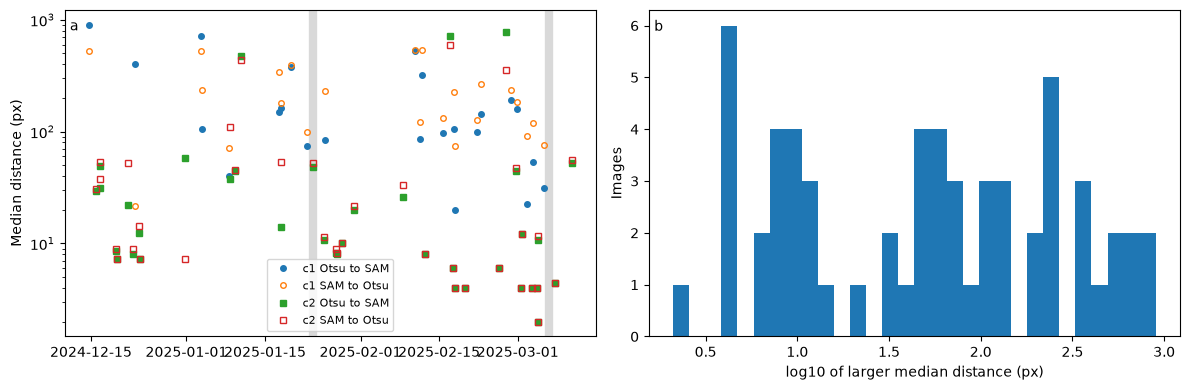

In [11]:
# distance between the two waterlines (full-res pixels)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, m in zip(['c1', 'c2'], 'os'):
    d = cmp_[cmp_.camera == c]
    ax[0].semilogy(d.time, d.d_otsu_sam_med, m, ms=4, label=f'{c} Otsu to SAM')
    ax[0].semilogy(d.time, d.d_sam_otsu_med, m, ms=4, mfc='none', label=f'{c} SAM to Otsu')
ax[0].set_ylabel('Median distance (px)')
ax[0].legend(fontsize=8)
mm.mark_surveys(ax[0])
ax[1].hist(np.log10(cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1).dropna() + 0.1), 30)
ax[1].set_xlabel('log10 of larger median distance (px)')
ax[1].set_ylabel('Images')
for a, l in zip(ax, 'ab'):
    a.text(0.01, 0.97, l, transform=a.transAxes, va='top')
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_compare.png', dpi=150)

C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_6032\112216102.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  ex = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).sort_values('d', ascending=False).head(8)


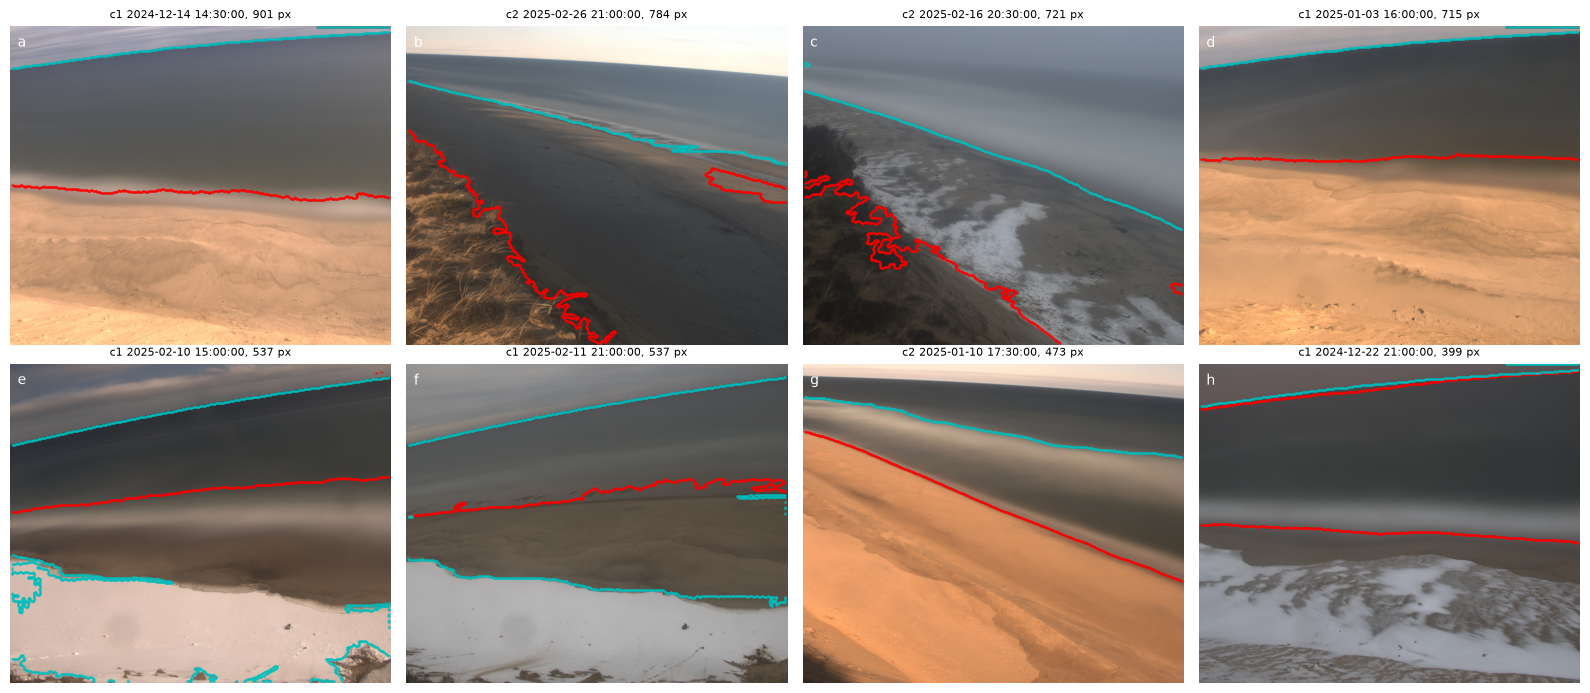

In [12]:
# the images where the two methods agree least (Otsu red, SAM cyan)
ex = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).sort_values('d', ascending=False).head(8)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, r, l in zip(ax.flat, ex.itertuples(), 'abcdefgh'):
    a.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
    for g, c in [(wl_px, 'r'), (wl_sam, 'c')]:
        p = g.get_group(r.path)
        a.plot(p.u, p.v, '.', c=c, ms=0.5)
    a.set_title(f'{r.camera} {r.time}, {r.d:.0f} px', fontsize=8)
    a.axis('off')
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top', color='w')
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_compare_examples.jpg', dpi=120)

## DEMs from the SAM waterlines
Once `waterlines_px_sam.csv` covers all images (`N_SAM = None`), run `make_dems.ipynb` with
`WL_CSV = OUT_DIR / 'waterlines_px_sam.csv'`, `DEM_DIR = OUT_DIR / 'dems_sam'` and `DEM_FIG_DIR = FIG_DIR / 'dems_sam'`
(and rename the csv outputs, or point `OUT_DIR` at a new folder holding a copy of `image_scan.csv`). Its detection
cell then finds nothing left to do and goes straight to the DEMs. This notebook and `make_movie.ipynb` run on
either set by changing `DEM_DIR`.

**References**
- Kirillov, A., Mintun, E., Ravi, N., Mao, H., Rolland, C., Gustafson, L., Xiao, T., Whitehead, S., Berg, A.C.,
  Lo, W.-Y., Dollár, P., Girshick, R., 2023. Segment Anything. *Proceedings of the IEEE/CVF International
  Conference on Computer Vision (ICCV)*, 4015–4026.
- Bruder, B.L., Brodie, K.L., 2020. CIRN Quantitative Coastal Imaging Toolbox. *SoftwareX* 12, 100582.